## Figures from a run

A Result's tables and `probatum.stats` hand out plain arrays and frames, so any plotting
library draws them; here matplotlib, whose figures show wherever a notebook does, GitHub's
viewer included. One run, a crossing of two averages on hourly Bitcoin bars of 2024 and
2025, drawn six ways.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import matplotlib.ticker
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 3.0.0, exchange-router 3.3.0


### The run

Binance's hourly BTCUSDT, fetched once into `bars/`, held while its five-day average is
above its twenty-day one, with a rebalance under 5% of the account left undone.

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

fast = probatum.ta.ema(data.close, length=24 * 5)
slow = probatum.ta.ema(data.close, length=24 * 20)

result = probatum.backtest(numpy.where(fast > slow, 1.0, 0.0), data=data,
                           venue="binance_spot", tolerance=0.05)

result

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,74.32,106.12,,,,,1
cagr_pct,31.98,43.50,,,,,1
volatility_pct,32.96,48.68,,,,,1
sharpe,1.01,0.99,-0.38,2.39,0.95,"delta method, Newey-West lag 15, floored at lag zero",
max_drawdown_pct,30.44,34.76,,,,,1
exposure_pct,51.64,,,,,,
num_trades,20,,,,,,
win_rate,0.30,,,,,,2
profit_factor,1.83,,,,,,2
costs,709,,,,,,


### Equity beside its baselines

The baselines are on the run's own bars and venue: the opening cash, buying and holding,
and the same policy with the costs of trading taken out.

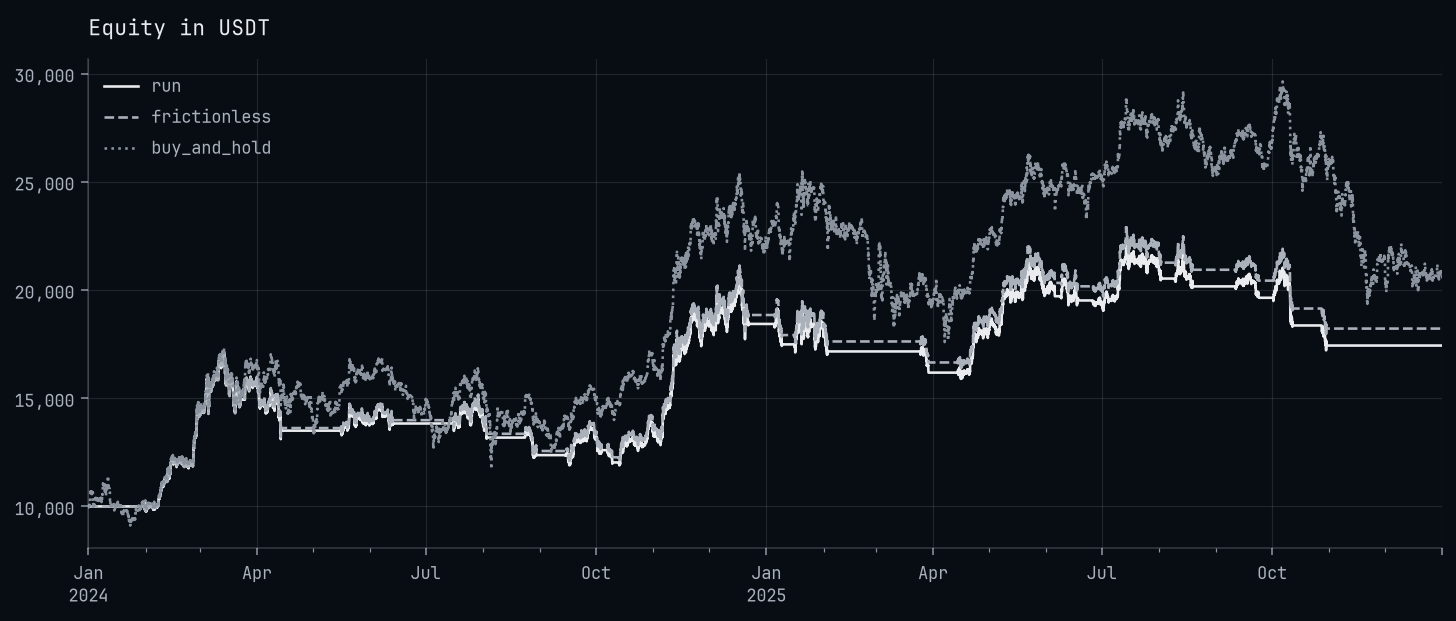

In [3]:
equity = result.baselines.to_pandas().set_index(keys="time")
equity["run"] = result.equity

axes = equity[["run", "frictionless", "buy_and_hold"]].plot(title="Equity in USDT", xlabel="")
axes.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))
matplotlib.pyplot.show()

### Drawdowns

The fall from the running peak at every bar, and the five deepest, each from its peak to
its trough and on to where it recovered, if it did.

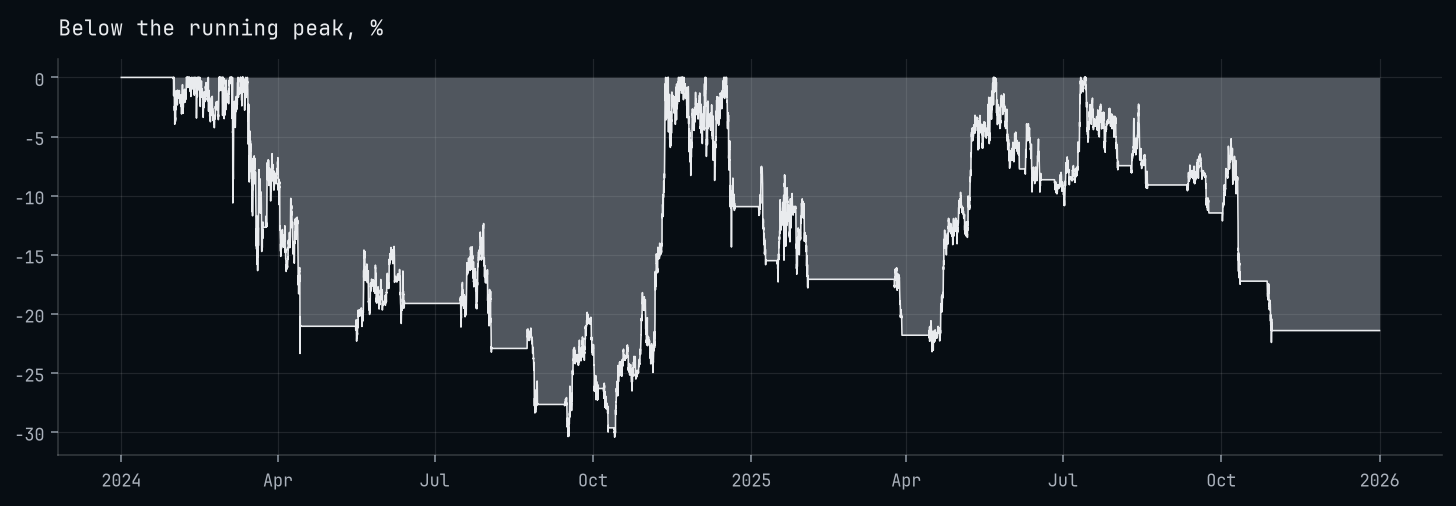

,peak_time,trough_time,recovered_time,depth_pct,bars_under
0,2024-03-14 06:00:00+00:00,2024-10-13 15:00:00+00:00,2024-11-12 06:00:00+00:00,30.44,5832
1,2024-12-17 14:00:00+00:00,2025-04-16 00:00:00+00:00,2025-05-21 14:00:00+00:00,23.21,3720
2,2025-07-14 07:00:00+00:00,2025-10-30 04:00:00+00:00,NaT,22.42,4096
3,2025-05-22 03:00:00+00:00,2025-07-02 00:00:00+00:00,2025-07-11 09:00:00+00:00,10.84,1206
4,2024-03-05 14:00:00+00:00,2024-03-05 19:00:00+00:00,2024-03-08 19:00:00+00:00,10.62,77


In [4]:
times = pandas.to_datetime(result.time, utc=True)
fall  = probatum.stats.drawdown(result)

figure, axes = matplotlib.pyplot.subplots(figsize=(10.0, 3.4))
axes.fill_between(times, -fall, 0.0, color="C1", alpha=0.45, linewidth=0.0)
axes.plot(times, -fall, linewidth=0.8)
axes.set_title(label="Below the running peak, %")
matplotlib.pyplot.show()

deepest = probatum.stats.drawdown_table(result, top=5).to_pandas()
deepest[["peak_time", "trough_time", "recovered_time", "depth_pct", "bars_under"]].round(
    decimals=2)

### Returns by month

Each calendar month's return, which compounded give the run's, above or below the axis by
their sign.

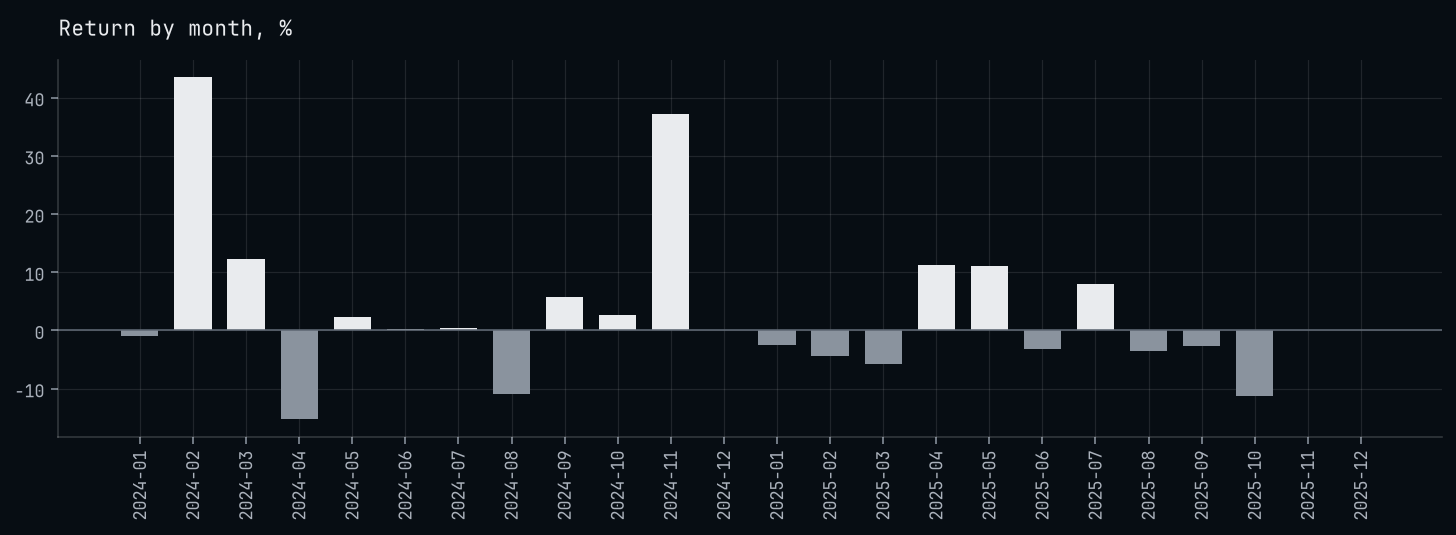

In [5]:
months = probatum.stats.period_returns(result, by="month").to_pandas()

figure, axes = matplotlib.pyplot.subplots(figsize=(10.0, 3.6))
axes.bar(months["start"].dt.strftime(date_format="%Y-%m"), months["return_pct"], width=0.7,
         color=numpy.where(months["return_pct"] >= 0.0, "C0", "C2"))
axes.axhline(y=0.0, color="C3", linewidth=0.8)
axes.tick_params(axis="x", labelrotation=90.0)
axes.set_title(label="Return by month, %")
matplotlib.pyplot.show()

### The Sharpe over time, and by quarter with its interval

Above, the Sharpe of the 90 days ending at each bar. Below, each quarter's own Sharpe from
`stats.segment`, which reads the quarter as a run of its own, with its 95% interval by the
delta method over the returns' long-run variance.

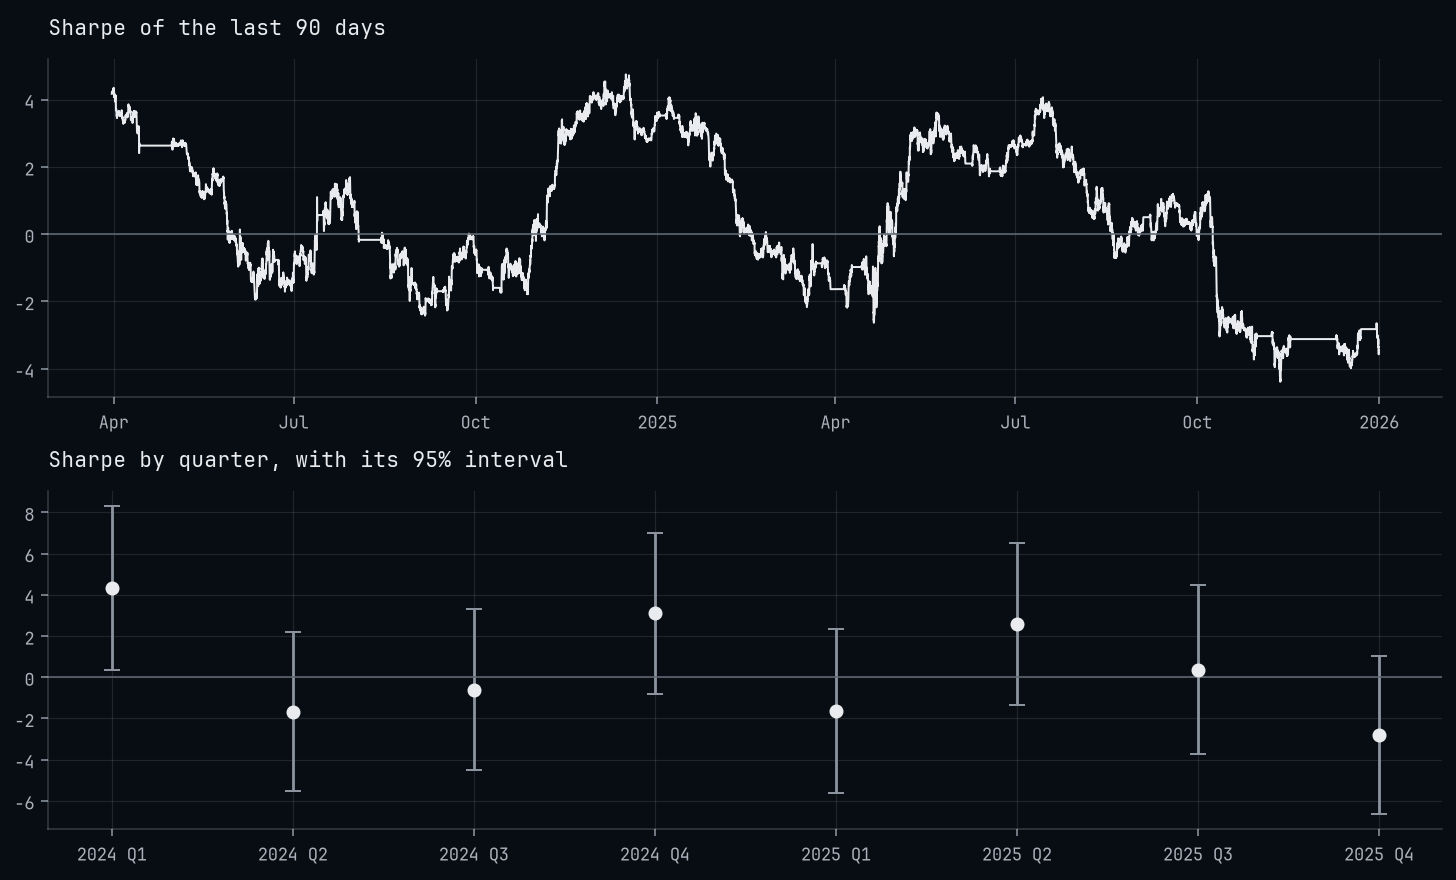

In [6]:
rolling  = probatum.stats.rolling_sharpe(result, window=24 * 90)
quarters = probatum.stats.period_returns(result, by="quarter").to_pandas()

points = []
for first, rows in zip(quarters["first_bar"], quarters["rows"]):
    record   = probatum.stats.segment(result, start=int(first), stop=int(first + rows))
    interval = record.interval("sharpe")
    points.append((record["sharpe"], interval.low, interval.high))

sharpe, low, high = numpy.array(points).T
labels = [f"{start.year} Q{start.quarter}" for start in quarters["start"]]

figure, (top, bottom) = matplotlib.pyplot.subplots(nrows=2, figsize=(10.0, 6.0),
                                                   height_ratios=[1.0, 1.0])
top.plot(times, rolling, linewidth=1.0)
top.axhline(y=0.0, color="C3", linewidth=0.8)
top.set_title(label="Sharpe of the last 90 days")
bottom.errorbar(labels, sharpe, yerr=[sharpe - low, high - sharpe], fmt="o", color="C0",
                ecolor="C2", elinewidth=1.4, capsize=4.0)
bottom.axhline(y=0.0, color="C3", linewidth=0.8)
bottom.set_title(label="Sharpe by quarter, with its 95% interval")
matplotlib.pyplot.show()

### Round trips

Each closed round trip's return, and against it the worst its price went before it closed,
the excursion a stop would have had to sit beyond.

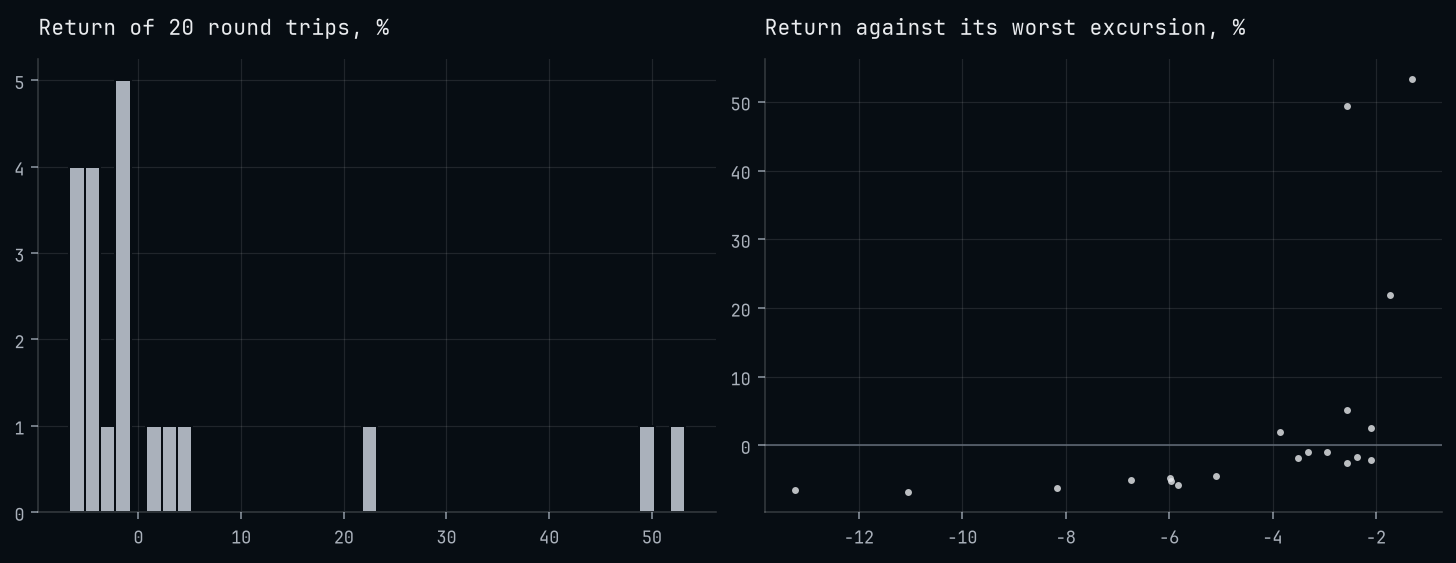

In [7]:
trades = result.trades.to_pandas()
closed = trades[~trades["open"]]

figure, (left, right) = matplotlib.pyplot.subplots(ncols=2, figsize=(10.0, 3.8))
left.hist(closed["ret"] * 100, bins=40, color="C1", edgecolor="#070d13")
left.set_title(label=f"Return of {len(closed)} round trips, %")
right.scatter(closed["worst"] * 100, closed["ret"] * 100, s=12.0, color="C0", alpha=0.8,
              linewidths=0.0)
right.axhline(y=0.0, color="C3", linewidth=0.8)
right.set_title(label="Return against its worst excursion, %")
matplotlib.pyplot.show()

### Where the money went

`stats.decompose` splits the change in equity into what the price moves made and what each
cost took, which add up to the whole of it.

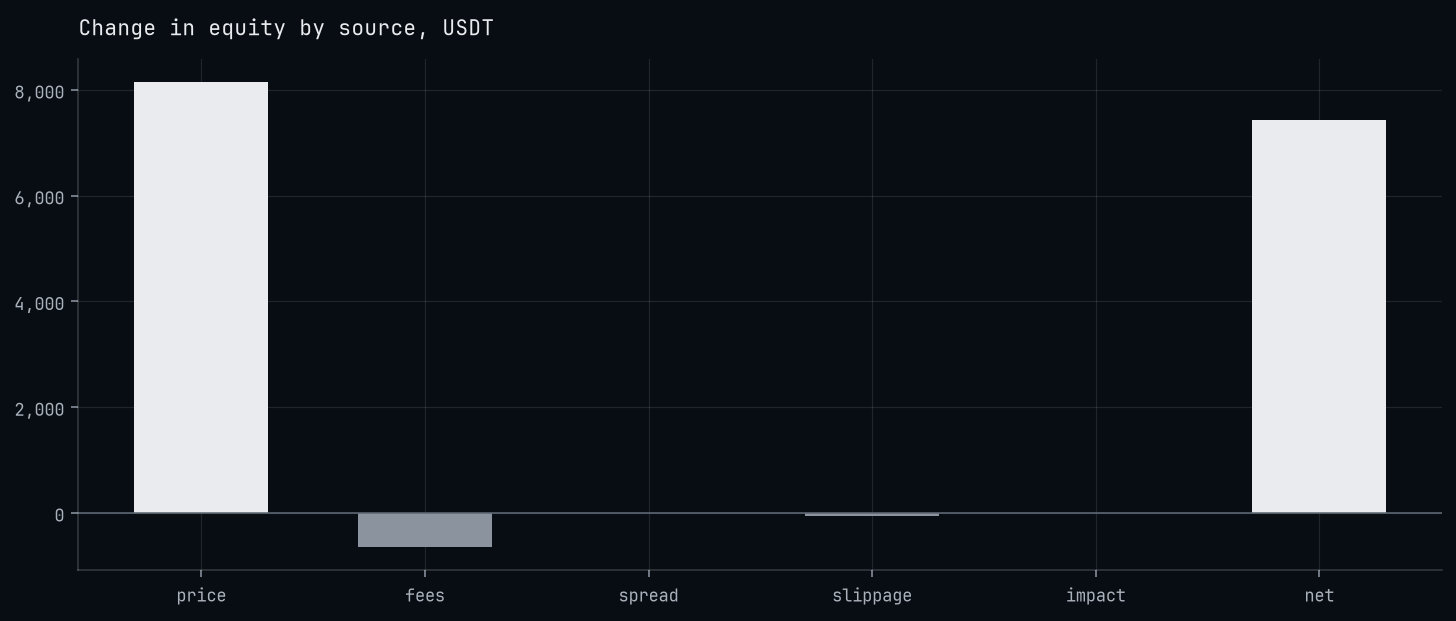

costs 708.93 USDT, 8.7% of the price pnl, turnover 19.8 a year


In [8]:
parts = probatum.stats.decompose(result)

steps = pandas.Series({"price": parts.price, "fees": -parts.fees, "spread": -parts.spread,
                       "slippage": -parts.slippage, "impact": -parts.impact,
                       "net": parts.net})

axes = steps.plot(kind="bar", width=0.6, rot=0, title="Change in equity by source, USDT",
                  color=numpy.where(steps >= 0.0, "C0", "C2"))
axes.axhline(y=0.0, color="C3", linewidth=0.8)
axes.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))
matplotlib.pyplot.show()

print(f"costs {parts.costs:,.2f} USDT, {parts.cost_share:.1f}% of the price pnl, "
      f"turnover {parts.turnover:,.1f} a year")